## [과제] 온라인 쇼핑몰 판매 데이터 분석


### 1. CSV 데이터 준비
예시 3행에 이어 17행을 추가하여 총 20행으로 만들었습니다. 코랩 드라이브 마운트 없이 바로 실행되도록 문자열로 CSV를 만들고, `exercise_sales.csv` 파일로도 저장합니다.

In [19]:
csv_text = """OrderID,CustomerID,Product,Category,Quantity,Price,OrderDate
1001,C001,Mouse,Electronics,2,25.00,2025-06-01
1002,C002,Keyboard,Electronics,1,45.00,2025-06-01
1003,C003,T-shirt,Fashion,3,15.00,2025-06-02
1004,C004,Jeans,Fashion,1,55.00,2025-06-10
1005,C001,Monitor,Electronics,1,180.00,2025-06-15
1006,C005,Novel,Books,4,12.00,2025-06-18
1007,C006,Sneakers,Fashion,2,70.00,2025-06-25
1008,C002,Headphones,Electronics,1,90.00,2025-07-02
1009,C007,Textbook,Books,2,35.00,2025-07-05
1010,C003,Jacket,Fashion,1,120.00,2025-07-11
1011,C008,Mouse,Electronics,3,25.00,2025-07-14
1012,C004,Novel,Books,5,12.00,2025-07-20
1013,C009,T-shirt,Fashion,4,15.00,2025-07-27
1014,C005,Keyboard,Electronics,2,45.00,2025-08-03
1015,C010,Dictionary,Books,1,28.00,2025-08-06
1016,C006,Jeans,Fashion,2,55.00,2025-08-12
1017,C007,Monitor,Electronics,2,180.00,2025-08-19
1018,C001,Textbook,Books,3,35.00,2025-08-23
1019,C008,Sneakers,Fashion,1,70.00,2025-08-28
1020,C009,Headphones,Electronics,2,90.00,2025-08-30
"""

with open("exercise_sales.csv", "w", encoding="utf-8") as f:
    f.write(csv_text)
print("exercise_sales.csv 저장 완료")

exercise_sales.csv 저장 완료


### 2. Pandas

In [20]:
import pandas as pd
print("pandas 버전:", pd.__version__)

pandas 버전: 3.0.6


#### 2-1. CSV 읽기 → DataFrame

In [21]:
df = pd.read_csv("exercise_sales.csv", parse_dates=["OrderDate"])
print(type(df))
print(df)

<class 'pandas.DataFrame'>
    OrderID CustomerID     Product     Category  Quantity  Price  OrderDate
0      1001       C001       Mouse  Electronics         2   25.0 2025-06-01
1      1002       C002    Keyboard  Electronics         1   45.0 2025-06-01
2      1003       C003     T-shirt      Fashion         3   15.0 2025-06-02
3      1004       C004       Jeans      Fashion         1   55.0 2025-06-10
4      1005       C001     Monitor  Electronics         1  180.0 2025-06-15
5      1006       C005       Novel        Books         4   12.0 2025-06-18
6      1007       C006    Sneakers      Fashion         2   70.0 2025-06-25
7      1008       C002  Headphones  Electronics         1   90.0 2025-07-02
8      1009       C007    Textbook        Books         2   35.0 2025-07-05
9      1010       C003      Jacket      Fashion         1  120.0 2025-07-11
10     1011       C008       Mouse  Electronics         3   25.0 2025-07-14
11     1012       C004       Novel        Books         5   1

#### 2-2. 조회: head / tail / 열 / 구조 확인

In [22]:
print("앞 3개")
print(df.head(3))
print("\n뒤 3개")
print(df.tail(3))
print("\n'Product' 열")
print(df["Product"])

앞 3개
   OrderID CustomerID   Product     Category  Quantity  Price  OrderDate
0     1001       C001     Mouse  Electronics         2   25.0 2025-06-01
1     1002       C002  Keyboard  Electronics         1   45.0 2025-06-01
2     1003       C003   T-shirt      Fashion         3   15.0 2025-06-02

뒤 3개
    OrderID CustomerID     Product     Category  Quantity  Price  OrderDate
17     1018       C001    Textbook        Books         3   35.0 2025-08-23
18     1019       C008    Sneakers      Fashion         1   70.0 2025-08-28
19     1020       C009  Headphones  Electronics         2   90.0 2025-08-30

'Product' 열
0          Mouse
1       Keyboard
2        T-shirt
3          Jeans
4        Monitor
5          Novel
6       Sneakers
7     Headphones
8       Textbook
9         Jacket
10         Mouse
11         Novel
12       T-shirt
13      Keyboard
14    Dictionary
15         Jeans
16       Monitor
17      Textbook
18      Sneakers
19    Headphones
Name: Product, dtype: str


In [23]:
print("인덱스:", df.index)
print("열 이름:", df.columns)
print("\n자료형")
print(df.dtypes)
print("\n기초 통계")
print(df.describe())

인덱스: RangeIndex(start=0, stop=20, step=1)
열 이름: Index(['OrderID', 'CustomerID', 'Product', 'Category', 'Quantity', 'Price',
       'OrderDate'],
      dtype='str')

자료형
OrderID                int64
CustomerID               str
Product                  str
Category                 str
Quantity               int64
Price                float64
OrderDate     datetime64[us]
dtype: object

기초 통계
          OrderID   Quantity       Price            OrderDate
count    20.00000  20.000000   20.000000                   20
mean   1010.50000   2.150000   60.100000  2025-07-13 22:48:00
min    1001.00000   1.000000   12.000000  2025-06-01 00:00:00
25%    1005.75000   1.000000   25.000000  2025-06-17 06:00:00
50%    1010.50000   2.000000   45.000000  2025-07-12 12:00:00
75%    1015.25000   3.000000   75.000000  2025-08-07 12:00:00
max    1020.00000   5.000000  180.000000  2025-08-30 00:00:00
std       5.91608   1.182103   50.409794                  NaN


#### 2-3. 파생 열 추가: 총매출 = Quantity × Price, 월(Month)

In [24]:
df["Total"] = df["Quantity"] * df["Price"]
df["Month"] = df["OrderDate"].dt.strftime("%Y-%m")
print(df[["OrderID", "Product", "Quantity", "Price", "Total", "Month"]])

    OrderID     Product  Quantity  Price  Total    Month
0      1001       Mouse         2   25.0   50.0  2025-06
1      1002    Keyboard         1   45.0   45.0  2025-06
2      1003     T-shirt         3   15.0   45.0  2025-06
3      1004       Jeans         1   55.0   55.0  2025-06
4      1005     Monitor         1  180.0  180.0  2025-06
5      1006       Novel         4   12.0   48.0  2025-06
6      1007    Sneakers         2   70.0  140.0  2025-06
7      1008  Headphones         1   90.0   90.0  2025-07
8      1009    Textbook         2   35.0   70.0  2025-07
9      1010      Jacket         1  120.0  120.0  2025-07
10     1011       Mouse         3   25.0   75.0  2025-07
11     1012       Novel         5   12.0   60.0  2025-07
12     1013     T-shirt         4   15.0   60.0  2025-07
13     1014    Keyboard         2   45.0   90.0  2025-08
14     1015  Dictionary         1   28.0   28.0  2025-08
15     1016       Jeans         2   55.0  110.0  2025-08
16     1017     Monitor        

#### 2-4. 집계: 카테고리별 / 월별 / 상품별

In [25]:
cat_sales = df.groupby("Category")["Total"].sum()
print("카테고리별 총매출")
print(cat_sales)

month_sales = df.groupby("Month")["Total"].sum()
print("\n월별 총매출")
print(month_sales)

product_qty = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)
print("\n상품별 판매 수량")
print(product_qty)

카테고리별 총매출
Category
Books           311.0
Electronics    1070.0
Fashion         600.0
Name: Total, dtype: float64

월별 총매출
Month
2025-06    563.0
2025-07    475.0
2025-08    943.0
Name: Total, dtype: float64

상품별 판매 수량
Product
Novel         9
T-shirt       7
Mouse         5
Textbook      5
Monitor       3
Headphones    3
Keyboard      3
Jeans         3
Sneakers      3
Jacket        1
Dictionary    1
Name: Quantity, dtype: int64


### 3. NumPy

In [26]:
import numpy as np
print("numpy 버전:", np.__version__)

numpy 버전: 2.5.3


#### 3-1. DataFrame → ndarray

In [27]:
qty = df["Quantity"].to_numpy()
price = df["Price"].to_numpy()
total = df["Total"].to_numpy()

print("qty  :", qty)
print("price:", price)
print("total:", total)
print("\n타입:", type(qty))
print("축의 개수(ndim):", qty.ndim)
print("크기(shape):", qty.shape)

qty  : [2 1 3 1 1 4 2 1 2 1 3 5 4 2 1 2 2 3 1 2]
price: [ 25.  45.  15.  55. 180.  12.  70.  90.  35. 120.  25.  12.  15.  45.
  28.  55. 180.  35.  70.  90.]
total: [ 50.  45.  45.  55. 180.  48. 140.  90.  70. 120.  75.  60.  60.  90.
  28. 110. 360. 105.  70. 180.]

타입: <class 'numpy.ndarray'>
축의 개수(ndim): 1
크기(shape): (20,)


#### 3-2. 2차원 배열 만들기 + reshape

In [28]:
mat = np.array([qty, price, total])   # (3, 20): 행=변수, 열=주문
print(mat.shape)
print(mat)

mat_T = mat.T                         # (20, 3): 행=주문, 열=변수
print("\n전치 후 shape:", mat_T.shape)

grid = total.reshape((4, 5))          # 20개 값을 4x5로
print("\n총매출 4x5 reshape")
print(grid)

(3, 20)
[[  2.   1.   3.   1.   1.   4.   2.   1.   2.   1.   3.   5.   4.   2.
    1.   2.   2.   3.   1.   2.]
 [ 25.  45.  15.  55. 180.  12.  70.  90.  35. 120.  25.  12.  15.  45.
   28.  55. 180.  35.  70.  90.]
 [ 50.  45.  45.  55. 180.  48. 140.  90.  70. 120.  75.  60.  60.  90.
   28. 110. 360. 105.  70. 180.]]

전치 후 shape: (20, 3)

총매출 4x5 reshape
[[ 50.  45.  45.  55. 180.]
 [ 48. 140.  90.  70. 120.]
 [ 75.  60.  60.  90.  28.]
 [110. 360. 105.  70. 180.]]


#### 3-3. 슬라이싱 / 정수 인덱싱

In [29]:
print("첫 번째 주문 [수량, 단가, 총매출]:", mat_T[0, :])
print("총매출 열 앞 5개:", mat_T[:5, 2])
print("정수 인덱싱 (0행 2열, 4행 1열):", mat_T[[0, 4], [2, 1]])

첫 번째 주문 [수량, 단가, 총매출]: [ 2. 25. 50.]
총매출 열 앞 5개: [ 50.  45.  45.  55. 180.]
정수 인덱싱 (0행 2열, 4행 1열): [ 50. 180.]


#### 3-4. 연산

In [30]:
print("총매출 합계:", total.sum())
print("총매출 평균:", total.mean().round(2))
print("총매출 최대/최소:", total.max(), total.min())
print("가장 큰 주문 인덱스:", total.argmax(), "→ OrderID", df.loc[total.argmax(), "OrderID"])

# 벡터 연산: 10% 할인 가정
discounted = price * 0.9
print("\n10% 할인 단가 앞 5개:", discounted[:5])

# 불리언 인덱싱: 총매출 100 이상인 주문
big = total[total >= 100]
print("총매출 100 이상 주문:", big)

# 행렬 곱 (np.dot): 수량 벡터와 단가 벡터의 내적 = 전체 매출
print("\nnp.dot(qty, price) =", np.dot(qty, price))

총매출 합계: 1981.0
총매출 평균: 99.05
총매출 최대/최소: 360.0 28.0
가장 큰 주문 인덱스: 16 → OrderID 1017

10% 할인 단가 앞 5개: [ 22.5  40.5  13.5  49.5 162. ]
총매출 100 이상 주문: [180. 140. 120. 110. 360. 105. 180.]

np.dot(qty, price) = 1981.0


### 4. Matplotlib

In [31]:
!pip install matplotlib

In [32]:
import matplotlib.pyplot as plt
print("matplotlib 버전:", plt.matplotlib.__version__)

matplotlib 버전: 3.11.2


#### 4-1. 라인 플롯: 주문별 총매출 추이

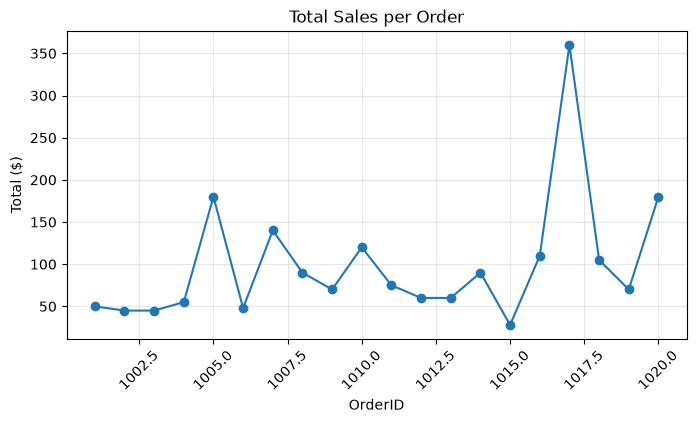

In [33]:
plt.figure(figsize=(8, 4))
plt.title("Total Sales per Order")
plt.plot(df["OrderID"], total, marker="o")
plt.xlabel("OrderID")
plt.ylabel("Total ($)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

#### 4-2. 라인 추가 + 범례: 카테고리별 월별 매출

Category  Books  Electronics  Fashion
Month                                
2025-06    48.0        275.0    240.0
2025-07   130.0        165.0    180.0
2025-08   133.0        630.0    180.0


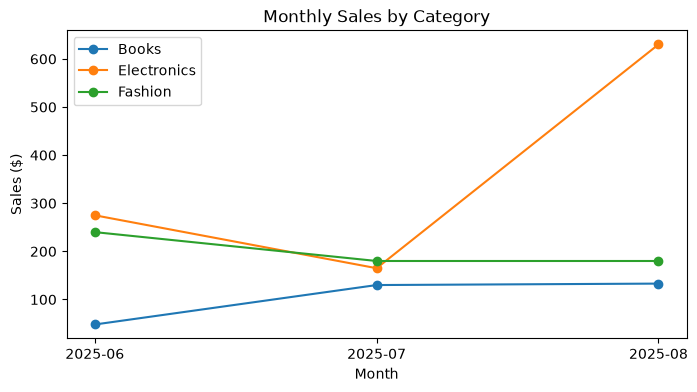

In [34]:
pivot = df.pivot_table(index="Month", columns="Category", values="Total", aggfunc="sum", fill_value=0)
print(pivot)

plt.figure(figsize=(8, 4))
plt.title("Monthly Sales by Category")
for cat in pivot.columns:
    plt.plot(pivot.index, pivot[cat], marker="o")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.legend(list(pivot.columns))
plt.show()

#### 4-3. 막대 그래프: 카테고리별 총매출

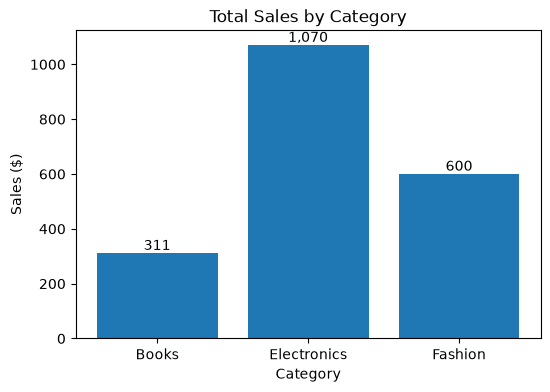

In [35]:
plt.figure(figsize=(6, 4))
plt.title("Total Sales by Category")
plt.bar(cat_sales.index, cat_sales.values)
plt.xlabel("Category")
plt.ylabel("Sales ($)")
for i, v in enumerate(cat_sales.values):
    plt.text(i, v, f"{v:,.0f}", ha="center", va="bottom")
plt.show()

#### 4-4. 막대 그래프: 상품별 판매 수량 / 원형 그래프: 매출 비중

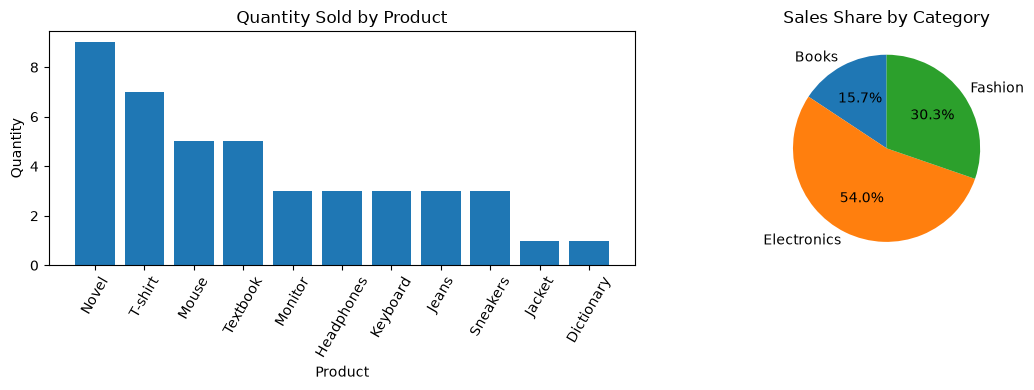

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(product_qty.index, product_qty.values)
axes[0].set_title("Quantity Sold by Product")
axes[0].set_xlabel("Product")
axes[0].set_ylabel("Quantity")
axes[0].tick_params(axis="x", rotation=60)

axes[1].pie(cat_sales.values, labels=cat_sales.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Sales Share by Category")

plt.tight_layout()
plt.show()

#### 4-5. 산점도: 수량 vs 총매출

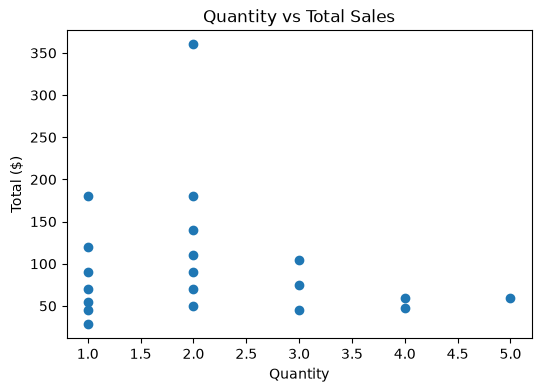

In [37]:
plt.figure(figsize=(6, 4))
plt.title("Quantity vs Total Sales")
plt.scatter(qty, total)
plt.xlabel("Quantity")
plt.ylabel("Total ($)")
plt.show()

### 5. 정리
- **Pandas**: CSV → DataFrame, 파생 열, `groupby` 집계로 데이터 요약
- **NumPy**: `to_numpy()`로 ndarray 변환 후 shape·슬라이싱·벡터 연산
- **Matplotlib**: 라인(추이), 막대(비교), 원형(비중), 산점도(관계)로 시각화